# Hansen annual deforestation maps

1. a 30 m map for every year 2001–2025 on Earth Engine, shown interactively and exportable (sections 4 and 8);
2. one small map of Guinea per year, from the hexagon table already computed in `deforestation_hansen.ipynb`
   (section 5, no Earth Engine compute);
3. a year-by-year comparison: how much was lost, and whether it is in the same places (section 6);
4. how each Hansen release reports the same years (section 7): do new releases change the loss of past years?

### What the annual map shows

Forest = canopy > `CANOPY_THRESHOLD` % in 2000 (the Global Forest Watch convention, as in `deforestation_hansen.ipynb`). 
For year Y every land pixel gets one status:

| Status | Meaning |
|---|---|
| 0 | not forest in 2000 |
| 1 | forest, still standing at the end of Y |
| 2 | forest lost **during** Y (`lossyear` = Y − 2000) |
| 3 | forest lost in an earlier year |

Regrowth is not added back: Hansen's `gain` band only covers 2000–2012. 
A pixel that is lost stays lost, so the maps show **gross** loss of the 2000 forest, not the forest that exists in year Y.

## 1. Setup

In [2]:
import json
import time
from datetime import datetime, timezone
from pathlib import Path

import ee
import geemap
import geopandas as gpd
import h3
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
from matplotlib.collections import PolyCollection

PROJECT_ROOT = Path.cwd().parent                     # .../Guinea_Methodology

KEY_CANDIDATES = [
    PROJECT_ROOT / "gee-account.json",
    PROJECT_ROOT / "Land Use-Deforestation" / "landuse_tool" / "credentials" / "tribal-mapper-275801-7b57ce84f3bd.json",
]
KEY_FILE = next((path for path in KEY_CANDIDATES if path.exists()), None)

OUTPUT_DIR = Path.cwd() / "output_datasets"
ECOREGIONS_GPKG = OUTPUT_DIR / "ecoregions_guinea.gpkg"   # Guinea boundary layer
H3_LOSS_PARQUET = OUTPUT_DIR / "hansen_loss_by_h3_res6_polygon_year.parquet"  # made by deforestation_hansen.ipynb

RELEASES_PARQUET = OUTPUT_DIR / "hansen_loss_by_release_year.parquet"  # section 7
RELEASES_RUN_JSON = OUTPUT_DIR / "hansen_loss_by_release_year.run.json"
EXPORT_LOG_JSON = OUTPUT_DIR / "hansen_annual_exports.json"             # section 8: exports started, to follow them

## 2. Parameters

In [3]:
HANSEN_ASSET = "UMD/hansen/global_forest_change_2025_v1_13"
FIRST_YEAR, LAST_YEAR = 2001, 2025
YEARS = list(range(FIRST_YEAR, LAST_YEAR + 1))
CANOPY_THRESHOLD = 30          # one of 0, 10, 30, 50: the thresholds in the tables of deforestation_hansen.ipynb
METHOD_CHANGE_YEAR = 2013      # Hansen method change (investigate_tier.ipynb)
MIN_FOREST_KM2 = 1             # hexagons with less forest in 2000 are left out of the year-to-year correlation
COMPARE_YEARS = (2012, 2024)   # two years to put side by side (section 6.3)
FORCE_RECOMPUTE = False        # True = call Earth Engine again even if the parquet already exists

# Earlier releases, to see how the same years change from one release to the next (section 7).
HANSEN_RELEASES = [
    "UMD/hansen/global_forest_change_2015",
    "UMD/hansen/global_forest_change_2015_v1_3",
    "UMD/hansen/global_forest_change_2016_v1_4",
    "UMD/hansen/global_forest_change_2017_v1_5",
    "UMD/hansen/global_forest_change_2018_v1_6",
    "UMD/hansen/global_forest_change_2019_v1_7",
    "UMD/hansen/global_forest_change_2020_v1_8",
    "UMD/hansen/global_forest_change_2021_v1_9",
    "UMD/hansen/global_forest_change_2022_v1_10",
    "UMD/hansen/global_forest_change_2023_v1_11",
    "UMD/hansen/global_forest_change_2024_v1_12",
    HANSEN_ASSET,
]
MAX_EECU_HOURS_RELEASES = 15   # stop section 7 if the first release projects above this for all releases

EXPORT_DESTINATION = None      # section 8: None (no export), "asset", "gcs" or "drive"
ASSET_FOLDER = "guinea"        # asset folder under projects/<GEE project>/assets/, or folder name in the bucket
GCS_BUCKET = None              # bucket name, needed for "gcs"
DRIVE_FOLDER = "guinea_exports"

## 3. Connect to Earth Engine

In [4]:
with open(KEY_FILE) as f:
    key_info = json.load(f)

SERVICE_ACCOUNT = key_info["client_email"]
GEE_PROJECT = key_info["project_id"]

credentials = ee.ServiceAccountCredentials(SERVICE_ACCOUNT, key_file=str(KEY_FILE))
ee.Initialize(credentials=credentials, project=GEE_PROJECT)

guinea_boundary = gpd.read_file(ECOREGIONS_GPKG, layer="guinea_boundary")
guinea_ee = ee.Geometry(guinea_boundary.geometry.iloc[0].simplify(0.001).__geo_interface__)  # ~100 m simplification

ecoregions = gpd.read_file(ECOREGIONS_GPKG, layer="ecoregions_guinea")  # from ecoregions.ipynb
ecoregion_borders = ee.FeatureCollection(
    [ee.Feature(ee.Geometry(geometry.simplify(0.005).__geo_interface__), {"ECO_NAME": name})
     for name, geometry in zip(ecoregions["ECO_NAME"], ecoregions.geometry)]
).style(color="ffffff", fillColor="00000000", width=1)

## 4. The annual maps

### 4.1 Collect Annual Maps

In [5]:
hansen = ee.Image(HANSEN_ASSET)
HANSEN_CRS = "EPSG:4326"
HANSEN_TRANSFORM = [0.00025, 0, -180, 0, -0.00025, 80]  # native 0.00025° grid (≈ 27.5 m)

land = hansen.select("datamask").eq(1)
forest_2000 = hansen.select("treecover2000").gt(CANOPY_THRESHOLD)
loss_year = hansen.select("lossyear").unmask(0)  # masked where there was no loss; 0 = no loss

STATUS_CLASSES = {0: "Not forest in 2000", 1: "Forest", 2: "Lost this year", 3: "Lost in an earlier year"}
STATUS_COLORS = ["#e8e8e8", "#2e7d32", "#d7191c", "#fdae61"]
STATUS_VIS = {"min": 0, "max": 3, "palette": STATUS_COLORS}


def annual_status(year):
    """Status of every land pixel at the end of `year` (see the table at the top)."""
    lost_this_year = forest_2000.And(loss_year.eq(year - 2000))
    lost_before = forest_2000.And(loss_year.gt(0)).And(loss_year.lt(year - 2000))
    return (
        forest_2000.toByte().where(lost_before, 3).where(lost_this_year, 2)
        .updateMask(land)
        .rename("status")
        .set({"year": year, "system:time_start": ee.Date.fromYMD(year, 1, 1).millis()})
    )


annual_maps = ee.ImageCollection([annual_status(year) for year in YEARS])
print(f"{len(YEARS)} annual maps, {FIRST_YEAR}–{LAST_YEAR}")

25 annual maps, 2001–2025


In [6]:
def add_context_layers(m):
    """Satellite basemap and the layers shared by every map of this section (off by default)."""
    m.add_basemap("SATELLITE")
    m.add_layer(forest_2000.selfMask().clip(guinea_ee), {"palette": ["#2e7d32"]}, f"Forest 2000 (> {CANOPY_THRESHOLD}%)", False)
    m.add_layer(
        loss_year.updateMask(forest_2000.And(loss_year.gt(0))).clip(guinea_ee),
        {"min": 1, "max": LAST_YEAR - 2000, "palette": ["yellow", "orange", "red"]}, "Loss year (all years)", False,
    )
    m.add_layer(ecoregion_borders, {}, "Ecoregion borders", False)


STATUS_LEGEND = dict(zip(STATUS_CLASSES.values(), STATUS_COLORS))

m = geemap.Map(center=[10.4, -11], zoom=7)
add_context_layers(m)
m.add_time_slider(annual_maps.map(lambda image: image.clip(guinea_ee)), STATUS_VIS, labels=[str(year) for year in YEARS],
                  time_interval=1, layer_name="Annual status")
m.add_legend(title="Status", legend_dict=STATUS_LEGEND)
m

Map(center=[10.4, -11], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright', t…

### 4.3 Year Comparison

In [7]:
import ipywidgets as widgets


def year_map(year):
    """A map like 4.2 showing the annual status of one year."""
    year_m = geemap.Map(center=[8.6, -9.2], zoom=10, height="600px")  # Guinée Forestière; zoom out to move elsewhere
    add_context_layers(year_m)
    year_m.add_layer(annual_status(year).clip(guinea_ee), STATUS_VIS, "Annual status")
    year_m.add_legend(title="Status", legend_dict=STATUS_LEGEND)
    return year_m


def show_year(year_m):
    """Callback for a drop-down: replace the map's annual status layer (same layer name = replaced)."""
    return lambda change: year_m.add_layer(annual_status(change["new"]).clip(guinea_ee), STATUS_VIS, "Annual status")


panels, maps = [], []
for year in COMPARE_YEARS:
    year_m = year_map(year)
    picker = widgets.Dropdown(options=YEARS, value=year, description="Year", layout=widgets.Layout(width="180px"))
    picker.observe(show_year(year_m), names="value")
    maps.append(year_m)
    panels.append(widgets.VBox([picker, year_m], layout=widgets.Layout(width="50%")))
for attribute in ("center", "zoom"):
    widgets.jslink((maps[0], attribute), (maps[1], attribute))
widgets.HBox(panels)

## 5. Annual Map

Each year is shown on the H3 hexagons. Colour = forest lost **that year**, as % of the hexagon's land.

All panels share the same colour scale, so they can be compared directly. Titles in red are the years after the
method change. Grey lines are the ecoregion borders.

In [8]:
h3_table = pd.read_parquet(H3_LOSS_PARQUET)
forest_column = f"forest2000_gt{CANOPY_THRESHOLD}_km2"

hex_land = h3_table.groupby("h3_id")["land_km2"].sum()
hex_forest_2000 = h3_table.groupby("h3_id")[forest_column].sum()
hex_loss = (
    h3_table[h3_table["lossyear"] > 0]
    .pivot_table(index="h3_id", columns="year", values=forest_column, aggfunc="sum", fill_value=0)
    .reindex(index=hex_land.index, columns=YEARS, fill_value=0)
)
hex_loss_pct_land = 100 * hex_loss.div(hex_land, axis=0)
hex_outlines = [[(lng, lat) for lat, lng in h3.cell_to_boundary(h3_id)] for h3_id in hex_land.index]


def plot_hexagons(ax, values, cmap, vmin, vmax):
    """Draw the hexagons coloured by `values` (in the order of hex_land). Much faster than GeoDataFrame.plot."""
    collection = PolyCollection(hex_outlines, array=np.asarray(values), cmap=cmap, linewidths=0)
    collection.set_clim(vmin, vmax)
    ax.add_collection(collection)
    ax.autoscale_view()
    ax.set_aspect("equal")
    return collection


print(f"{len(hex_outlines):,} hexagons, {hex_loss.to_numpy().sum():,.0f} km² lost {FIRST_YEAR}–{LAST_YEAR}")

8,496 hexagons, 24,096 km² lost 2001–2025


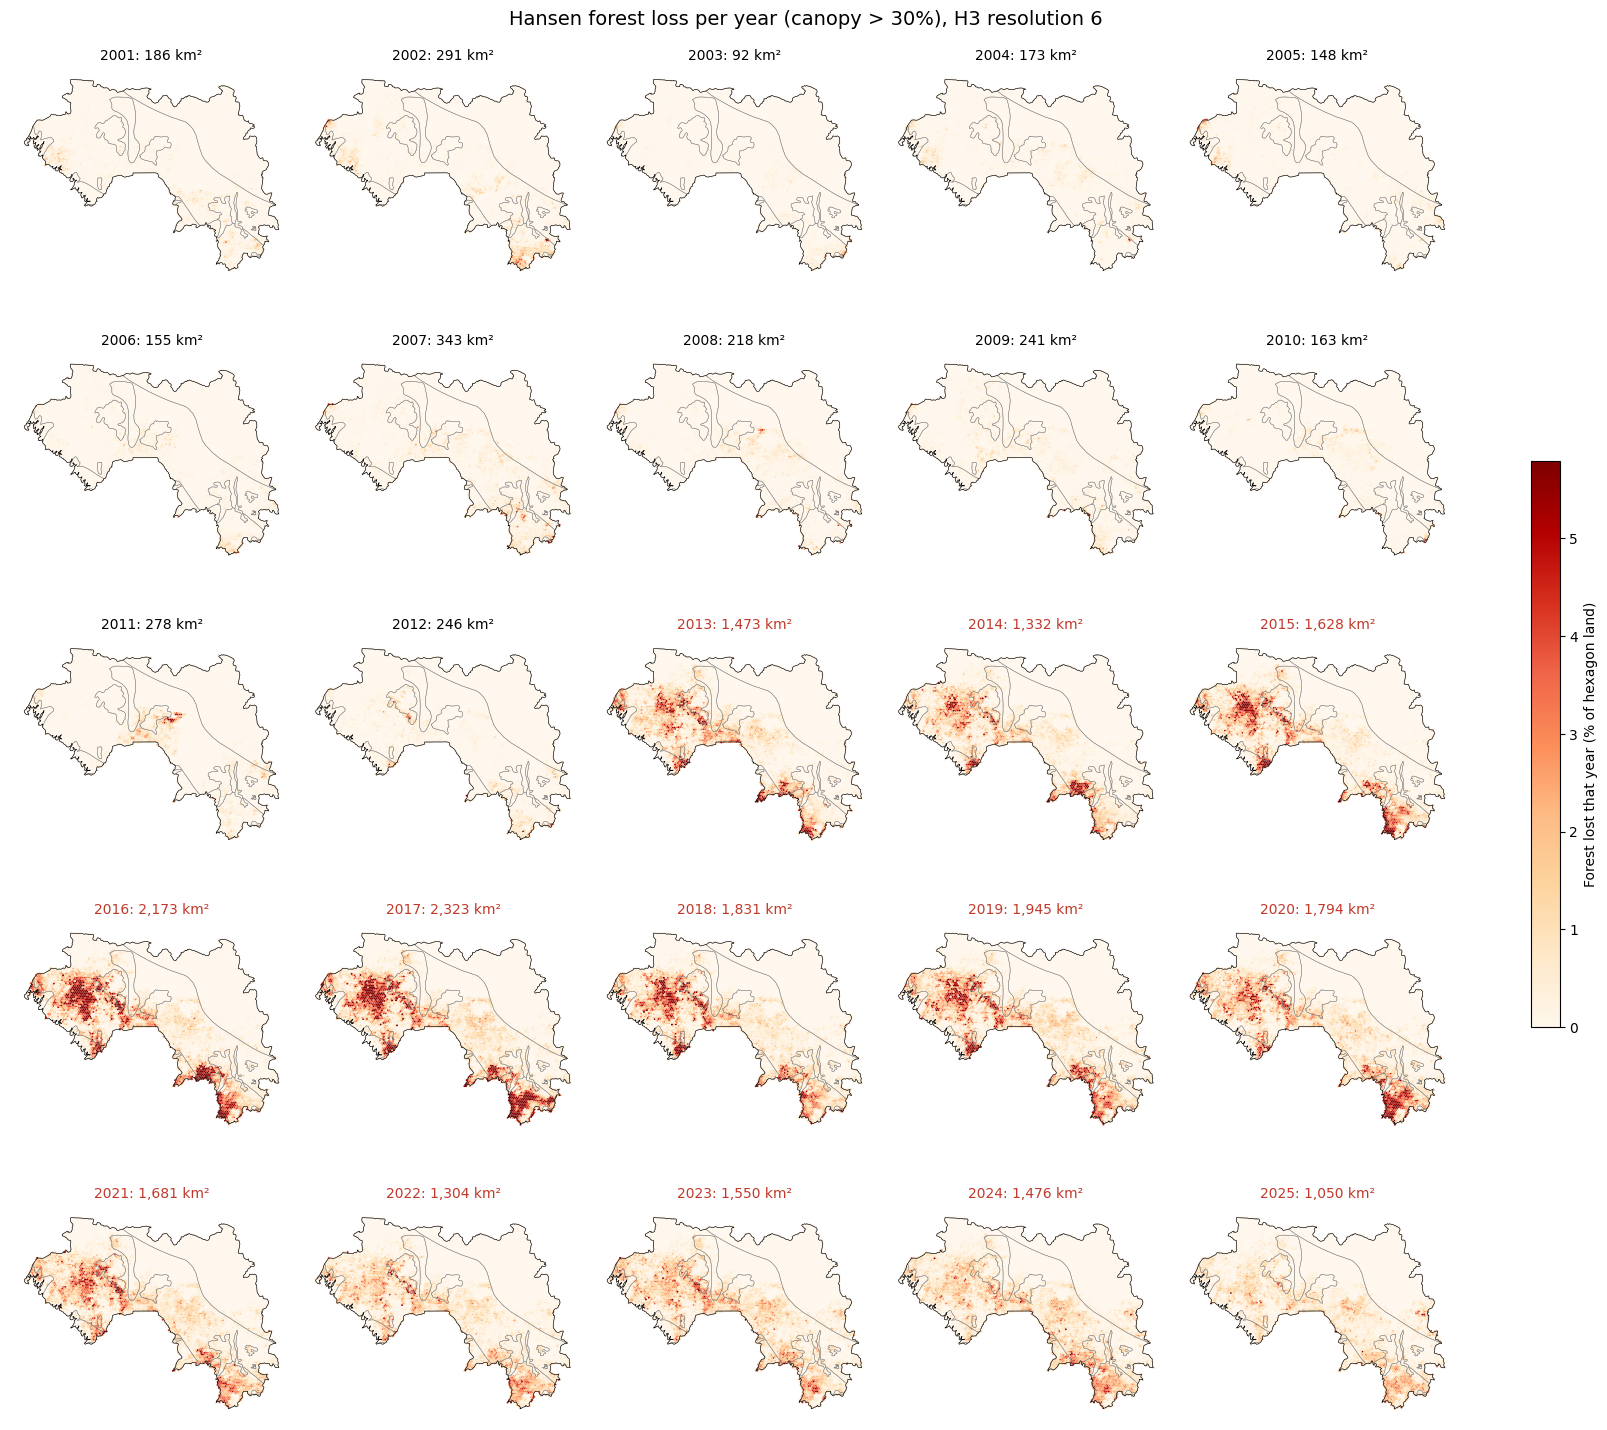

In [9]:
N_COLUMNS = 5
color_max = np.percentile(hex_loss_pct_land.to_numpy(), 99.5)  # a few extreme hexagons would wash out the rest
n_rows = int(np.ceil(len(YEARS) / N_COLUMNS))

fig, axes = plt.subplots(n_rows, N_COLUMNS, figsize=(3.2 * N_COLUMNS, 2.9 * n_rows), constrained_layout=True)
for ax, year in zip(axes.flat, YEARS):
    plot_hexagons(ax, hex_loss_pct_land[year], "OrRd", 0, color_max)
    ecoregions.boundary.plot(ax=ax, color="grey", linewidth=0.3)
    guinea_boundary.boundary.plot(ax=ax, color="black", linewidth=0.4)
    ax.set_title(f"{year}: {hex_loss[year].sum():,.0f} km²", fontsize=10,
                 color="#c0392b" if year >= METHOD_CHANGE_YEAR else "black")
    ax.set_axis_off()
for ax in axes.flat[len(YEARS):]:
    ax.set_axis_off()
fig.colorbar(plt.cm.ScalarMappable(norm=plt.Normalize(0, color_max), cmap="OrRd"), ax=axes, shrink=0.4,
             label="Forest lost that year (% of hexagon land)")
fig.suptitle(f"Hansen forest loss per year (canopy > {CANOPY_THRESHOLD}%), H3 resolution 6", fontsize=14)
fig.savefig(OUTPUT_DIR / f"hansen_annual_maps_h3_gt{CANOPY_THRESHOLD}.png", dpi=150)
plt.show()

## 6. Comparing the years

### 6.1 How much, and how spread out

| Column | Meaning |
|---|---|
| `loss_km2` | forest lost that year |
| `loss_%_of_2000_forest` | the same, as a share of the 2000 forest |
| `times_2001_2012_mean` | the year's loss divided by the average year before the method change |
| `hexagons_with_loss_over_0.1_km2` | how many hexagons lose more than 0.1 km² (10 ha) that year: how widespread *substantial* loss is (almost every forested hexagon loses a few pixels every year, so "any loss" says little) |
| `top_10%_hexagons_share_%` | share of the year's loss in the 10 % of hexagons with the most loss: how concentrated it is |

The second table is the mean annual loss before and after the method change. 
Real deforestation changes at different times in different regions; a change of detection method shifts every region in the same year. 
A jump of the same size, in the same year, in every ecoregion therefore points to the method.

In [10]:
national = pd.DataFrame({"loss_km2": hex_loss.sum()})
national.index.name = "year"
national["loss_%_of_2000_forest"] = 100 * national["loss_km2"] / hex_forest_2000.sum()
national["change_vs_previous_year_%"] = 100 * national["loss_km2"].pct_change()
national["times_2001_2012_mean"] = national["loss_km2"] / national.loc[national.index < METHOD_CHANGE_YEAR, "loss_km2"].mean()
national["hexagons_with_loss_over_0.1_km2"] = (hex_loss > 0.1).sum()
top_count = int(0.1 * len(hex_loss))
national["top_10%_hexagons_share_%"] = hex_loss.apply(lambda year: 100 * year.nlargest(top_count).sum() / year.sum())
national["period"] = np.where(national.index < METHOD_CHANGE_YEAR, f"{FIRST_YEAR}–{METHOD_CHANGE_YEAR - 1}",
                              f"{METHOD_CHANGE_YEAR}–{LAST_YEAR}")

for column, title in [("loss_km2", "Forest lost per year (km²)"),
                      ("hexagons_with_loss_over_0.1_km2", "Number of hexagons losing more than 0.1 km²"),
                      ("top_10%_hexagons_share_%", "Share of the year's loss in the top 10 % hexagons (%)")]:
    fig = px.bar(national.reset_index(), x="year", y=column, color="period",
                 color_discrete_sequence=["#b0b0b0", "#c0392b"], labels={column: "", "year": "Year"},
                 title=title, template="plotly_white", height=320)
    fig.show()
display(national.round(2))

annual_by_ecoregion = (
    h3_table[h3_table["lossyear"] > 0].groupby(["ECO_NAME", "year"])[forest_column].sum().unstack(fill_value=0)
)
jump_by_ecoregion = pd.DataFrame({
    f"mean_loss_{FIRST_YEAR}_{METHOD_CHANGE_YEAR - 1}_km2": annual_by_ecoregion.loc[:, :METHOD_CHANGE_YEAR - 1].mean(axis=1),
    f"mean_loss_{METHOD_CHANGE_YEAR}_{LAST_YEAR}_km2": annual_by_ecoregion.loc[:, METHOD_CHANGE_YEAR:].mean(axis=1),
})
jump_by_ecoregion["times_higher_after"] = jump_by_ecoregion.iloc[:, 1] / jump_by_ecoregion.iloc[:, 0]
jump_by_ecoregion.round(1)

,loss_km2,loss_%_of_2000_forest,change_vs_previous_year_%,times_2001_2012_mean,hexagons_with_loss_over_0.1_km2,top_10%_hexagons_share_%,period
year,,,,,,,
2001,185.96,0.23,NaN,0.88,439,62.40,2001–2012
2002,291.23,0.36,56.61,1.38,698,68.43,2001–2012
2003,91.76,0.11,-68.49,0.43,156,69.52,2001–2012
2004,173.21,0.21,88.76,0.82,385,62.47,2001–2012
2005,148.22,0.18,-14.43,0.70,295,66.19,2001–2012
2006,154.92,0.19,4.52,0.73,336,62.64,2001–2012
2007,343.49,0.42,121.72,1.63,991,54.75,2001–2012
2008,218.07,0.27,-36.51,1.03,553,59.74,2001–2012
2009,241.25,0.30,10.63,1.14,632,54.34,2001–2012


,mean_loss_2001_2012_km2,mean_loss_2013_2025_km2,times_higher_after
ECO_NAME,,,
Guinean forest-savanna,127.5,1056.1,8.3
Guinean mangroves,3.1,26.6,8.6
Guinean montane forests,26.0,196.8,7.6
West Sudanian savanna,9.1,27.5,3.0
Western Guinean lowland forests,45.6,351.5,7.7


### 6.2 Spatial Consistency

Each cell is the rank correlation (Spearman) between two years' maps: the loss of every hexagon as a share of its 2000 forest, for hexagons with at least `MIN_FOREST_KM2` of forest in 2000.

- High values next to the diagonal: loss stays in the same places from one year to the next (active fronts).
- A **block** before 2013 and another after, with low values between them: the geography of the loss changed with
  the method, so early and late years do not describe the same thing.

In [11]:
forested = hex_forest_2000 >= MIN_FOREST_KM2
loss_rate = 100 * hex_loss[forested].div(hex_forest_2000[forested], axis=0)
year_similarity = loss_rate.corr(method="spearman")

fig = px.imshow(
    year_similarity.round(2), color_continuous_scale="Viridis", zmin=0, zmax=1,
    labels={"x": "Year", "y": "Year", "color": "Spearman"},
    title=f"How similar the loss maps of two years are ({forested.sum():,} forested hexagons)",
    template="plotly_white",
)
for line in ("vline", "hline"):
    getattr(fig, f"add_{line}")(METHOD_CHANGE_YEAR - 0.5, line_dash="dash", line_color="white")
fig.update_layout(height=600)
fig.show()

next_year_similarity = pd.Series({year: year_similarity.loc[year - 1, year] for year in YEARS[1:]}, name="similarity_to_previous_year")
next_year_similarity.round(2).to_frame().T

,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,...,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
similarity_to_previous_year,0.43,0.46,0.34,0.46,0.52,0.48,0.54,0.43,0.39,0.28,...,0.8,0.78,0.77,0.77,0.76,0.75,0.71,0.66,0.66,0.62


### 6.3 Comparing two years

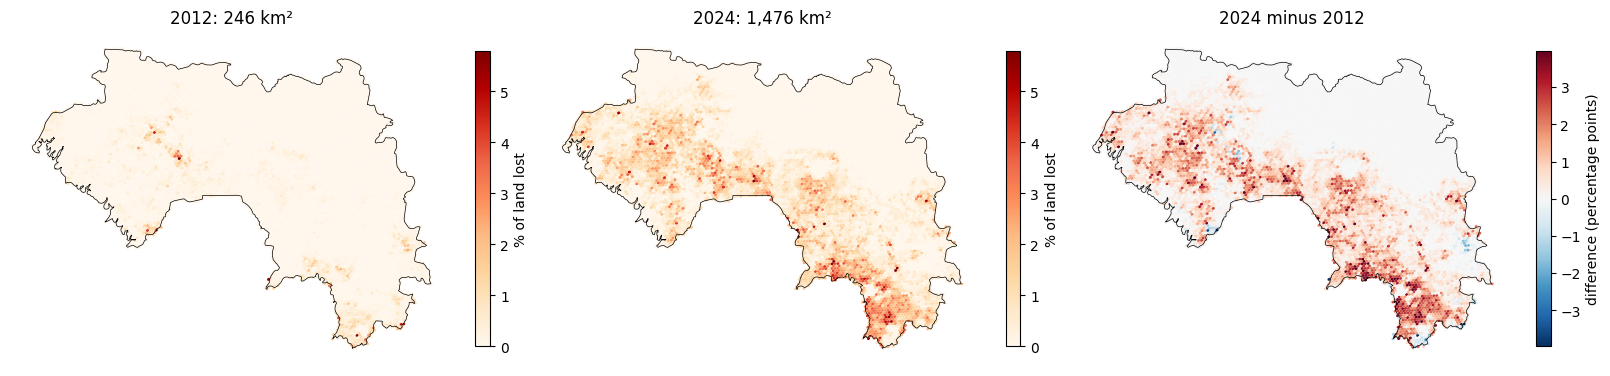

In [12]:
year_a, year_b = COMPARE_YEARS
difference = hex_loss_pct_land[year_b] - hex_loss_pct_land[year_a]
difference_max = np.percentile(np.abs(difference), 99.5)

fig, axes = plt.subplots(1, 3, figsize=(16, 5), constrained_layout=True)
for ax, year in zip(axes[:2], COMPARE_YEARS):
    fig.colorbar(plot_hexagons(ax, hex_loss_pct_land[year], "OrRd", 0, color_max), ax=ax, shrink=0.6,
                 label="% of land lost")
    ax.set_title(f"{year}: {hex_loss[year].sum():,.0f} km²")
fig.colorbar(plot_hexagons(axes[2], difference, "RdBu_r", -difference_max, difference_max), ax=axes[2], shrink=0.6,
             label="difference (percentage points)")
axes[2].set_title(f"{year_b} minus {year_a}")
for ax in axes:
    guinea_boundary.boundary.plot(ax=ax, color="black", linewidth=0.5)
    ax.set_axis_off()
plt.show()

## 7. How each Hansen release reports the same years

Every year UMD publishes a new release with one more year of loss. If a release also re-processed earlier years,
"the loss of 2015" would depend on the release used, and numbers from different releases could not be mixed.
Here the loss per year in Guinea is computed with **every release still on Earth Engine**, for the same canopy
threshold, to check it.

One grouped sum per release over Guinea at 30 m, like section 4 of `deforestation_hansen.ipynb` (that one measured
~0.7–1.4 EECU-hours). The cost is printed after the first release, and the section stops if all releases would cost
more than `MAX_EECU_HOURS_RELEASES`. Each release is saved as soon as it is computed: re-running only computes the
missing ones.

In [13]:
def get_info_with_eecu(request):
    """Compute an Earth Engine object and return (result, seconds, eecu_seconds).

    eecu_seconds is None if the profile could not be fetched (it is sometimes not ready on the server yet).
    """
    profile_ids = []
    start = time.perf_counter()
    with ee.data.profiling(profile_ids.append):
        result = request.getInfo()
    seconds = time.perf_counter() - start

    get_profiles = ee.ApiFunction.lookup("Profile.getProfiles").call
    for attempt in range(5):
        try:
            profile_text = get_profiles(ids=profile_ids).getInfo()
        except ee.EEException:
            time.sleep(2 * (attempt + 1))
            continue
        # The profile is a table; its first column is EECU-seconds per operation ("-" when negligible).
        eecu_seconds = sum(
            float(line.split()[0]) for line in profile_text.splitlines()[1:] if line.split() and line.split()[0] != "-"
        )
        return result, seconds, round(eecu_seconds, 1)
    return result, seconds, None


def release_name(asset):
    return asset.split("global_forest_change_")[1]  # e.g. "2025_v1_13"


def release_loss_by_year(asset):
    """Forest 2000 (> CANOPY_THRESHOLD) area of Guinea grouped by loss year, for one release."""
    image = ee.Image(asset)
    request = (
        ee.Image.pixelArea().divide(1e6)
        .addBands(image.select("lossyear").unmask(0).toInt())
        .updateMask(image.select("datamask").eq(1).And(image.select("treecover2000").gt(CANOPY_THRESHOLD)))
        .reduceRegion(
            reducer=ee.Reducer.sum().unweighted().group(groupField=1, groupName="lossyear"),
            geometry=guinea_ee,
            crs=HANSEN_CRS,
            crsTransform=HANSEN_TRANSFORM,
            maxPixels=1e13,
        )
    )
    result, seconds, eecu_seconds = get_info_with_eecu(request)
    table = pd.DataFrame(result["groups"]).rename(columns={"sum": "area_km2"})
    table["release"] = release_name(asset)
    return table, seconds, eecu_seconds


if RELEASES_PARQUET.exists() and not FORCE_RECOMPUTE:
    releases = pd.read_parquet(RELEASES_PARQUET)
    releases_run_info = json.loads(RELEASES_RUN_JSON.read_text()) if RELEASES_RUN_JSON.exists() else {}
else:
    releases, releases_run_info = None, {}

for asset in HANSEN_RELEASES:
    name = release_name(asset)
    already_done = releases is not None and name in set(releases["release"])
    if already_done or ("error" in releases_run_info.get(name, {}) and not FORCE_RECOMPUTE):
        continue
    try:
        table, seconds, eecu_seconds = release_loss_by_year(asset)
    except ee.EEException as error:
        print(f"{name}: not available, skipped ({error})")
        releases_run_info[name] = {"error": str(error)}
        RELEASES_RUN_JSON.write_text(json.dumps(releases_run_info, indent=2))
        continue
    releases = table if releases is None else pd.concat([releases, table], ignore_index=True)
    releases.to_parquet(RELEASES_PARQUET, index=False)
    releases_run_info[name] = {
        "computed_at_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
        "canopy_threshold": CANOPY_THRESHOLD,
        "seconds": round(seconds, 1),
        "eecu_seconds": eecu_seconds,
        "eecu_hours": None if eecu_seconds is None else round(eecu_seconds / 3600, 3),
    }
    RELEASES_RUN_JSON.write_text(json.dumps(releases_run_info, indent=2))
    print(f"{name}: computed in {seconds:.0f} s, {eecu_seconds} EECU-seconds")
    if eecu_seconds and eecu_seconds * len(HANSEN_RELEASES) / 3600 > MAX_EECU_HOURS_RELEASES:
        print(f"All releases would cost ~{eecu_seconds * len(HANSEN_RELEASES) / 3600:.1f} EECU-hours "
              f"> MAX_EECU_HOURS_RELEASES: stopped. Remove some releases or raise the limit.")
        break

if releases is None:
    raise RuntimeError("No release could be computed, see the messages above")
releases["lossyear"] = releases["lossyear"].astype(int)
releases["year"] = releases["lossyear"].where(releases["lossyear"] == 0, releases["lossyear"] + 2000)
release_order = [release_name(asset) for asset in HANSEN_RELEASES if release_name(asset) in set(releases["release"])]
print(f"Releases available: {release_order}")
print(f"Compute used: {sum((info.get('eecu_hours') or 0) for info in releases_run_info.values()):.2f} EECU-hours")

Releases available: ['2015', '2015_v1_3', '2016_v1_4', '2017_v1_5', '2018_v1_6', '2019_v1_7', '2020_v1_8', '2021_v1_9', '2022_v1_10', '2023_v1_11', '2024_v1_12', '2025_v1_13']
Compute used: 2.31 EECU-hours


### 7.1 Loss per year, per release

Rows are releases (oldest at the top), columns are loss years. Reading **down a column** shows how the loss of one year
changed from release to release: if the colour changes, that year was reprocessed. The second heatmap shows the
difference with the latest release: white everywhere means the releases never revised past years.

In [14]:
loss_by_release = (
    releases[releases["lossyear"] > 0]
    .pivot_table(index="release", columns="year", values="area_km2", aggfunc="sum")
    .reindex(release_order)
)
latest = release_order[-1]
difference_to_latest = loss_by_release - loss_by_release.loc[latest]

fig = px.imshow(
    loss_by_release.round(0), color_continuous_scale="OrRd", aspect="auto", text_auto=True,
    labels={"x": "Loss year", "y": "Release", "color": "km²"},
    title=f"Forest loss in Guinea per year, as reported by each release (canopy > {CANOPY_THRESHOLD}%)",
    template="plotly_white",
)
fig.update_layout(height=150 + 40 * len(release_order))
fig.show()

limit = np.nanmax(np.abs(difference_to_latest.to_numpy()))
fig = px.imshow(
    difference_to_latest.round(0), color_continuous_scale="RdBu_r", zmin=-limit, zmax=limit, aspect="auto",
    text_auto=True, labels={"x": "Loss year", "y": "Release", "color": "km²"},
    title=f"Difference with the latest release ({latest}): red = the older release reported more loss",
    template="plotly_white",
)
fig.update_layout(height=150 + 40 * len(release_order))
fig.show()

forest_2000_by_release = releases.groupby("release")["area_km2"].sum().reindex(release_order)
print("Forest 2000 area per release (km²), should be the same if treecover2000 was not changed:")
print(forest_2000_by_release.round(0).to_string())

Forest 2000 area per release (km²), should be the same if treecover2000 was not changed:
release
2015          81740.0
2015_v1_3     81740.0
2016_v1_4     81740.0
2017_v1_5     81740.0
2018_v1_6     81740.0
2019_v1_7     81740.0
2020_v1_8     81740.0
2021_v1_9     81740.0
2022_v1_10    81740.0
2023_v1_11    81740.0
2024_v1_12    81740.0
2025_v1_13    81740.0


In [15]:
plot_table = loss_by_release.reset_index().melt(id_vars="release", var_name="year", value_name="loss_km2").dropna()
fig = px.line(
    plot_table, x="year", y="loss_km2", color="release", markers=True,
    category_orders={"release": release_order}, color_discrete_sequence=px.colors.sequential.Viridis,
    labels={"loss_km2": "Forest loss (km²)", "year": "Loss year", "release": "Release"},
    title="The same years, as seen by each release", template="plotly_white",
)
fig.add_vline(x=METHOD_CHANGE_YEAR - 0.5, line_dash="dash", line_color="grey")
fig.show()

## 8. Notes

1. **Releases do not revise past years.** All 12 releases on Earth Engine (2015 → v1.13) give exactly the same loss
   for every year they share. The only exception is 2014, reported as 868 km² by the first 2015 release and 1,332 km²
   by all later ones. Numbers from different releases can therefore be mixed; the updates are **not** what makes the
   series inconsistent.
2. **The inconsistency is a break inside the series, in 2013.** Mean loss is 211 km²/yr in 2001–2012 and 1,659 km²/yr
   in 2013–2025 (× 7.9). Because past years are never reprocessed, every release keeps the break.
3. **The break is the method, not the forest.** It happens in the same year in every forest ecoregion (× 7.6 to × 8.6;
   × 3.0 in the West Sudanian savanna), and the number of hexagons losing more than 0.1 km² a year jumps from
   156–991 to 2,765–3,693. Real deforestation does not multiply by 8 everywhere in one year; a change in the detection
   method (Landsat 8 and the improved model, `investigate_tier.ipynb`) does.
4. **After 2013 the years are comparable with each other.** Consecutive loss maps are much more similar after 2013
   (Spearman 0.62–0.80) than before (0.28–0.54), and the loss slowly spreads: the top 10 % of hexagons hold 56 % of
   the loss in 2013 and 44 % in 2024. Part of the higher similarity is statistical (more loss makes ranks less noisy).
5. **A western hotspot appears in 2013** (Guinean forest-savanna, west of the country) and is almost absent before.
   Check it with the map of 4.3 (e.g. 2012 and 2016) before calling it a new deforestation front.
6. **Hansen loss is larger than official deforestation.** Over 2016–2020 Hansen loses 2,013 km²/yr. Guinea's REDD+
   reference level (NERF 2026, sample-based) reports 628 km²/yr of deforestation and 2,010 km²/yr of degradation
   (dense → open forest). Hansen's tree cover loss is closer to deforestation **plus** degradation than to
   deforestation alone. At the legal threshold (canopy > 10 %) Hansen loses even more: ~2,850 km²/yr over
   2016–2024, 4.5 × the official deforestation (`lulc_benchmark.ipynb`, 8.9).

### Implications for Deforestation Methodology

- **Use Hansen only within 2013–2025** for annual numbers, trends and year-to-year comparison. Never compute a
  2001–2025 trend or compare a year before 2013 with a year after it.
- **For a baseline before 2013, or a long series**, use a product made the same way every year (JRC TMF, GLC_FCS30D:
  see `lulc_benchmark.ipynb`) or our own classification of the HLS mosaics (`satellite_mosaic.ipynb`, from 2013).
- **The official reference period (NERF: 2016–2020) is inside the consistent part of Hansen**, so Hansen can be
  compared with it, but as **tree cover loss**, not deforestation. Report it under that name; to report deforestation
  in the national sense, use a product judged against the national definition (`lulc_benchmark.ipynb`, section 10)
  or a sample-based estimate like the NERF.
- **Canopy threshold**: Guinea's legal forest definition uses > 10 % canopy (Code forestier 2017, used in the NERF);
  this notebook uses 30 % (Global Forest Watch). Set `CANOPY_THRESHOLD = 10` and re-run to see the national-definition
  version (sections 5–6 already have the 10 % tables; section 7 is recomputed). At 10 % the forest of 2000 grows
  from ~82,000 to ~226,000 km², because most wooded savanna becomes forest: the threshold has to be agreed before
  any number is reported (`lulc_benchmark.ipynb`, 12.2).
- **Gross loss, no regrowth**: status 3 ("lost earlier") stays lost even if the land grew back. In fallow systems this
  overstates net loss; products that map forest every year (benchmark) show the regrowth.
- **Tree cover loss is not deforestation**: fallow clearing, fire, plantation harvest and canopy thinning are loss too.
  The land-cover products of the benchmark help tell what the loss became.
